<a href="https://colab.research.google.com/github/inosven/Neural-Networks-Zero-to-Hero/blob/main/Building_makemore_Part_3_Activations_%26_Gradients%2C_BatchNorm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')
with open('/content/drive/MyDrive/Colab Notebooks/Zero2Hero_Karpathy/Data/names.txt','r') as f:
  text = f.read().splitlines()

Mounted at /content/drive


In [2]:
import torch
import torch.nn.functional as F
from matplotlib import pyplot as plt
%matplotlib inline

In [3]:
words = text
len(words)

32033

In [5]:
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.']=0
itos = {i:s for s,i in stoi.items()}
vocab_size = len(itos)
vocab_size

27

In [6]:
block_size = 3 #input context size

def build_dataset(words):
  X,Y = [], []
  for w in words:
    context= [0] * 3
    for ch in w + '.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      context = context[1:]+[ix]
  X = torch.tensor(X)
  Y = torch.tensor(Y)
  print(X.shape, Y.shape)
  return X, Y

In [7]:
import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xval,Yval = build_dataset(words[n1:n2])
Xtes,Ytes = build_dataset(words[n2:])


torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [9]:
# MLP
n_emb = 10
n_hiddne = 200

g = torch.Generator().manual_seed(12312415)
C = torch.randn((vocab_size, n_emb), generator=g)
W1 = torch.randn((n_emb * block_size, n_hiddne), generator=g)
b1 = torch.randn(n_hiddne, generator=g)
W2 = torch.randn((n_hiddne, vocab_size), generator=g)
b2 = torch.rand(vocab_size, generator=g)

parameters = [C,W1,b1,W2,b2]

for p in parameters:
  p.requires_grad = True
print(sum(p.nelement() for p in parameters))

11897


In [11]:
max_steps = 200000
batch_size =32
lossi= []

for i in range(max_steps):
  # minibatch
  ix = torch.randint(0,Xtr.shape[0], (batch_size,), generator=g)
  Xb,Yb = Xtr[ix], Ytr[ix]

  # forward pass
  emb = C[Xb]
  embcat = emb.view(emb.shape[0],-1)
  hpreact = embcat @ W1 + b1 # h before activation
  h = torch.tanh(hpreact)
  logits = h @ W2 + b2
  loss = F.cross_entropy(logits,Yb)

  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()

  # update
  lr = 0.1 if i < 100000 else 0.01
  for p in parameters:
    p.data += -lr * p.grad

  # track
  if i%10000==0: # print every once in a while
    print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
  lossi.append(loss.log10().item())



      0/ 200000: 28.5239
  10000/ 200000: 2.8764
  20000/ 200000: 2.2694
  30000/ 200000: 2.8024
  40000/ 200000: 2.3227
  50000/ 200000: 2.3508
  60000/ 200000: 2.4706
  70000/ 200000: 2.1756
  80000/ 200000: 2.6379
  90000/ 200000: 2.0504
 100000/ 200000: 2.0422
 110000/ 200000: 2.4283
 120000/ 200000: 2.4096
 130000/ 200000: 1.8638
 140000/ 200000: 2.1345
 150000/ 200000: 1.7631
 160000/ 200000: 1.9328
 170000/ 200000: 2.2492
 180000/ 200000: 2.4537
 190000/ 200000: 2.2676


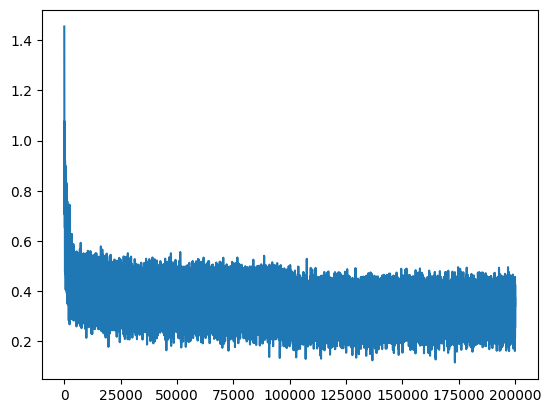

In [13]:
plt.plot(lossi)

In [14]:
@torch.no_grad # decorator distables gradient tracking
def split_loss(split):
  x,y = {
      'train': (Xtr,Ytr),
      'val': (Xval,Yval),
      'test': (Xtes,Ytes)
  }[split]
  emb = C[x]
  embcat = emb.view(emb.shape[0],-1)
  h = torch.tanh(embcat @ W1 +b1)
  logits = h @ W2 +b2
  loss = F.cross_entropy(logits, y)
  print(split, loss.item())


split_loss('train')
split_loss('val')

train 2.1361382007598877
val 2.1734800338745117


In [17]:
# predict
g = torch.Generator().manual_seed(1131551)
for _ in range(20):
  out = []
  context = [0]* block_size

  while True:
    # forwad pass
    emb = C[torch.tensor([context])]
    h = torch.tanh(emb.view(emb.shape[0],-1) @ W1 +b1)
    logits = h @ W2 +b2
    probs = F.softmax(logits,dim=1)

    # sample from distribution
    ix = torch.multinomial(probs, num_samples=1, generator=g).item()

    # shift context window and track the samples
    context = context[1:] + [ix]
    out.append(ix)
    if ix ==0:
      break
  print(''.join(itos[i] for i in out))

kassaelyssandavanden.
amue.
khalue.
mamyrie.
niyelyn.
knamon.
khirt.
melen.
dalaniom.
tkia.
maxani.
syx.
colvina.
brayah.
kashti.
amandey.
lit.
moa.
kendiat.
mis.
